In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [163]:
data = pd.read_csv("advertising.csv")
df = pd.DataFrame(data)
df


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [164]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [165]:
df.tail()

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,18.4


In [166]:
df.shape

(200, 4)

In [167]:
df.size

800

In [168]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [169]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [170]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [171]:
df.dtypes

,0
TV,float64
Radio,float64
Newspaper,float64
Sales,float64


In [172]:
df.isna().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [173]:
df.duplicated().sum()

np.int64(0)

In [174]:
df.corr(numeric_only=True)

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


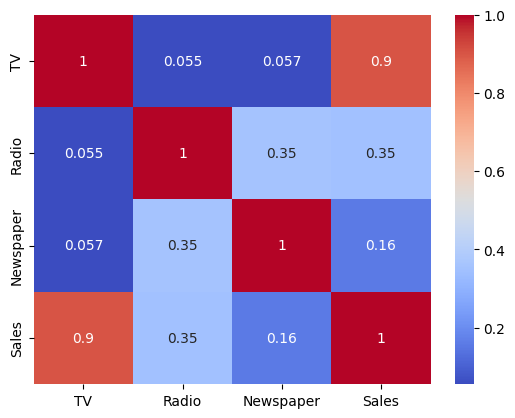

In [175]:
sns.heatmap(df.corr(numeric_only=True),annot = True,cmap = "coolwarm")
plt.show()

In [176]:
# feature slection
x = df.drop("Sales",axis= 1)
y = df["Sales"]

x = df.iloc[:,:-1]
y = df.iloc[:,-1]

Text(0.5, 1.0, 'TV vs Sales')

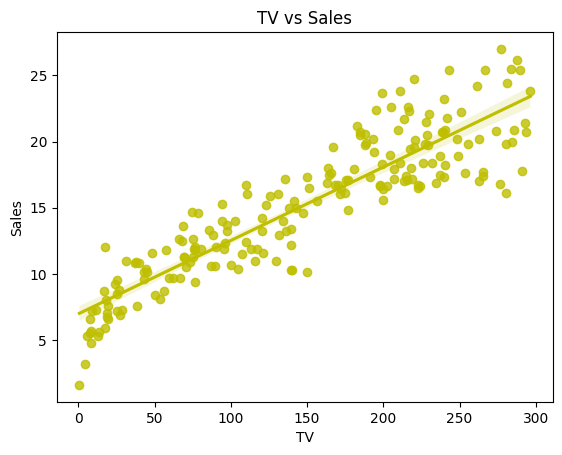

In [177]:
# regplot
# tv vs sales
sns.regplot(x=df["TV"],y=y,color = "y")
plt.title("TV vs Sales")



Text(0.5, 1.0, 'Radio vs Sales')

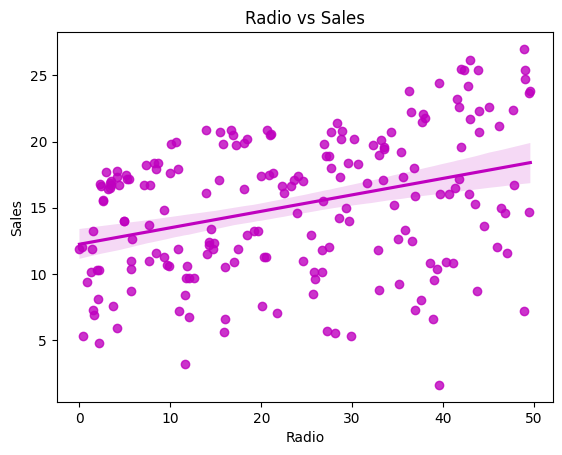

In [178]:
sns.regplot(x=df["Radio"],y=y,color = "m")
plt.title("Radio vs Sales")

Text(0.5, 1.0, 'Newspaper vs Sales')

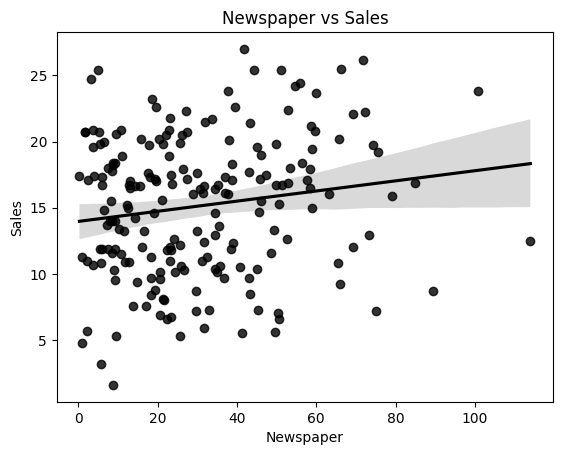

In [179]:
sns.regplot(x=df["Newspaper"],y=y,color = "0")
plt.title("Newspaper vs Sales")

In [180]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.30,random_state = 42)


In [181]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [182]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
y_pred

array([17.15991908, 20.53369503, 23.68914396,  9.5191455 , 21.60736836,
       12.78101318, 21.08636345,  8.76054246, 17.11499951, 16.68789636,
        8.97584663,  8.57645026, 18.33212325,  8.17863567, 12.64605571,
       14.94486946,  8.34939536, 17.83858948, 11.12172174, 20.37740648,
       20.9483297 , 13.04035779, 11.01360656, 22.51142595,  9.40369784,
        7.98591291, 20.86943368, 13.77882255, 10.83407064,  8.00419229,
       15.88597618, 10.7027424 , 20.9521718 , 10.84679243, 21.50720813,
       21.07347295, 12.22673775, 22.85273767, 12.57698182,  6.54597206,
       11.93411853, 15.23490068, 10.07411153,  9.52159696, 17.11786382,
        7.28032677, 10.49404864, 15.24356754, 11.20742176, 11.78392665,
       14.01472163, 14.59884572, 10.82722434,  9.55839415,  9.03749681,
       12.51183313, 10.52551021, 25.01900824,  7.99334943, 15.73916263])

In [183]:
print(model.predict(scaler.transform([[314.3,34.5,9.8]])))

[25.20780622]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [184]:
print(model.coef_)

[15.84617603  5.09425568  0.79792577]


In [185]:
print(model.intercept_)

4.783658285821831


In [186]:
df_1 = pd.DataFrame({'Actual_value': y_test,'Predicted_value': y_pred,'difference':y_test - y_pred})
df_1 = df_1.reset_index(drop=True)
df_1

,Actual_value,Predicted_value,difference
0,16.9,17.159919,-0.259919
1,22.4,20.533695,1.866305
2,21.4,23.689144,-2.289144
3,7.3,9.519146,-2.219146
4,24.7,21.607368,3.092632
5,12.6,12.781013,-0.181013
6,22.3,21.086363,1.213637
7,8.4,8.760542,-0.360542
8,16.5,17.115000,-0.615000
9,16.1,16.687896,-0.587896


In [187]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test,y_pred)
mae

1.1594875061090586

In [188]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test,y_pred)
mape

0.10536440823029315

In [189]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test,y_pred)
mse

2.54162403622915

In [190]:
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test,y_pred)
rmse

1.5942471691143598